In [1]:
import pandas as pd
import numpy as np

# Load the cleaned dataset
file_path = "cleaned_supply_chain_dataset.csv"

df = pd.read_csv(file_path)

# Convert date column using the actual date format
df["date"] = pd.to_datetime(
    df["date"],
    format="%d-%m-%Y",
    errors="raise"
)

# Preview the data
df.head()

,date,sku_id,warehouse_id,supplier_id,region,units_sold,inventory_level,supplier_lead_time_days,reorder_point,order_quantity,...,day_name,inventory_value,absolute_forecast_error,inventory_coverage_days,inventory_reorder_gap,forecast_error_pct,inventory_sales_value,reorder_status,unit_margin,margin_pct
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,...,Monday,8258.40,1.48,59.200000,213,14.800000,12124.16,Above Reorder Point,6.53,31.884766
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,...,Tuesday,8021.25,1.63,33.823529,196,-9.588235,11776.00,Above Reorder Point,6.53,31.884766
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,...,Wednesday,7533.00,4.62,15.428571,161,-13.200000,11059.20,Above Reorder Point,6.53,31.884766
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,...,Thursday,7198.20,4.57,21.500000,137,19.041667,10567.68,Above Reorder Point,6.53,31.884766
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,...,Friday,6905.25,2.30,23.571429,116,10.952381,10137.60,Above Reorder Point,6.53,31.884766


In [9]:
# Verify the date data type

print("Date data type:", df["date"].dtype)
print("Earliest date:", df["date"].min())
print("Latest date  :", df["date"].max())
print("Unique dates :", df["date"].nunique())

Date data type: datetime64[ns]
Earliest date: 2024-01-01 00:00:00
Latest date  : 2024-12-30 00:00:00
Unique dates : 365


In [28]:
# Calculate overall supply chain KPIs

total_units_sold = df["units_sold"].sum()
total_inventory_units = df["inventory_level"].sum()
total_inventory_value = df["inventory_value"].sum()
total_inventory_sales_value = df["inventory_sales_value"].sum()
total_order_quantity = df["order_quantity"].sum()
total_forecast = df["demand_forecast"].sum()

average_units_sold_per_record = df["units_sold"].mean()
average_inventory_level = df["inventory_level"].mean()

print(f"Total units sold                 : {total_units_sold:,.0f}")
print(f"Total inventory units            : {total_inventory_units:,.0f}")
print(f"Total inventory value            : ${total_inventory_value:,.2f}")
print(f"Potential inventory sales value  : ${total_inventory_sales_value:,.2f}")
print(f"Total replenishment quantity     : {total_order_quantity:,.0f}")
print(f"Total forecasted demand          : {total_forecast:,.2f}")
print(f"Average units sold per SKU-Warehouse-Day   : {average_units_sold_per_record:.2f}")
print(f"Average inventory per record     : {average_inventory_level:.2f}")

Total units sold                 : 1,829,979
Total inventory units            : 43,026,411
Total inventory value            : $525,243,991.12
Potential inventory sales value  : $785,352,698.13
Total replenishment quantity     : 1,758,615
Total forecasted demand          : 1,832,485.53
Average units sold per SKU-Warehouse-Day   : 20.05
Average inventory per record     : 471.52


In [31]:
# Calculate total demand by day

daily_demand = (
    df.groupby("date", as_index=False)["units_sold"]
    .sum()
    .rename(columns={"units_sold": "total_units_sold"})
)

# Display the first 10 days
daily_demand.head(10)

,date,total_units_sold
0,2024-01-01,5054
1,2024-01-02,5072
2,2024-01-03,5278
3,2024-01-04,5144
4,2024-01-05,5208
5,2024-01-06,5178
6,2024-01-07,5447
7,2024-01-08,5322
8,2024-01-09,5412
9,2024-01-10,5464


In [32]:
# Calculate daily demand statistics

daily_demand_stats = daily_demand["total_units_sold"].describe()

daily_demand_stats

count     365.000000
mean     5013.641096
std      1818.424708
min      2294.000000
25%      3185.000000
50%      5030.000000
75%      6815.000000
max      7702.000000
Name: total_units_sold, dtype: float64

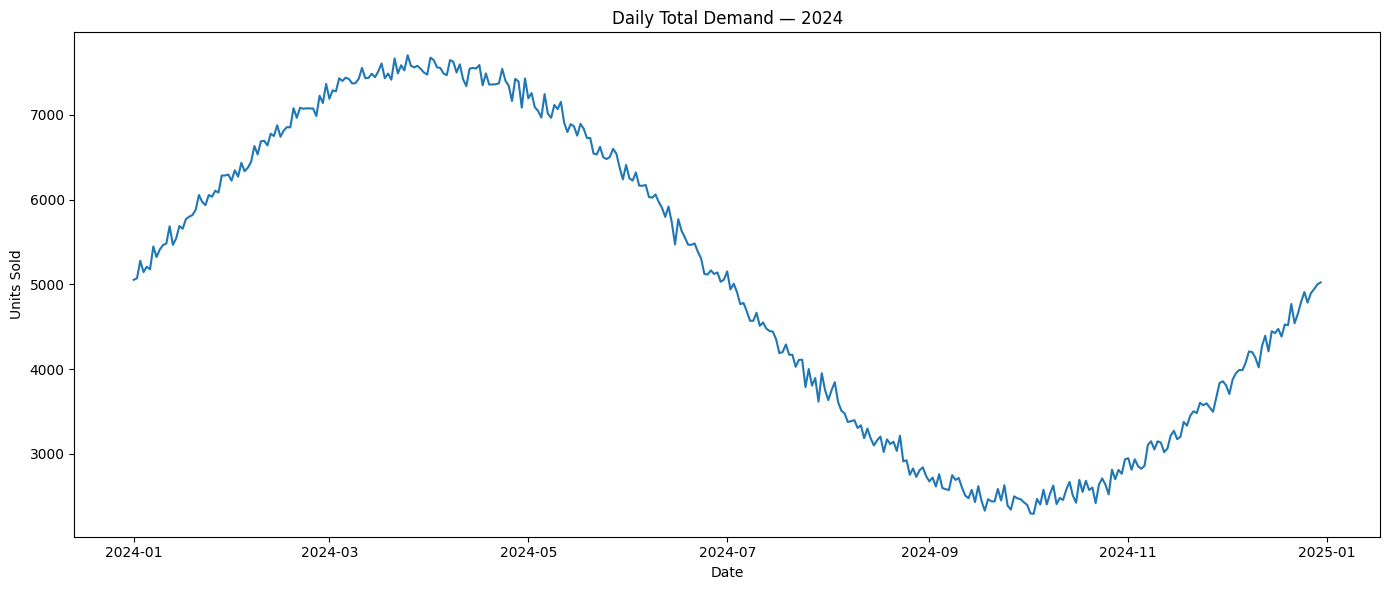

In [33]:
import matplotlib.pyplot as plt

# Plot total daily demand over time

plt.figure(figsize=(14, 6))

plt.plot(
    daily_demand["date"],
    daily_demand["total_units_sold"]
)

plt.title("Daily Total Demand — 2024")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.tight_layout()
plt.show()

In [35]:
# Calculate average demand by day of the week

weekly_demand = (
    df.groupby("day_name")["units_sold"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

weekly_demand

day_name
Monday       20.080075
Tuesday      20.062231
Wednesday    19.994538
Thursday     20.040462
Friday       20.075462
Saturday     20.019692
Sunday       20.109000
Name: units_sold, dtype: float64

In [36]:
# Calculate total demand by month

monthly_demand = (
    df.groupby(["year", "month", "month_name"], as_index=False)["units_sold"]
    .sum()
    .rename(columns={"units_sold": "total_units_sold"})
    .sort_values(["year", "month"])
)

monthly_demand

,year,month,month_name,total_units_sold
0,2024,1,January,176681
1,2024,2,February,197188
2,2024,3,March,231596
3,2024,4,April,223793
4,2024,5,May,210841
5,2024,6,June,170013
6,2024,7,July,134915
7,2024,8,August,99019
8,2024,9,September,76304
9,2024,10,October,79599


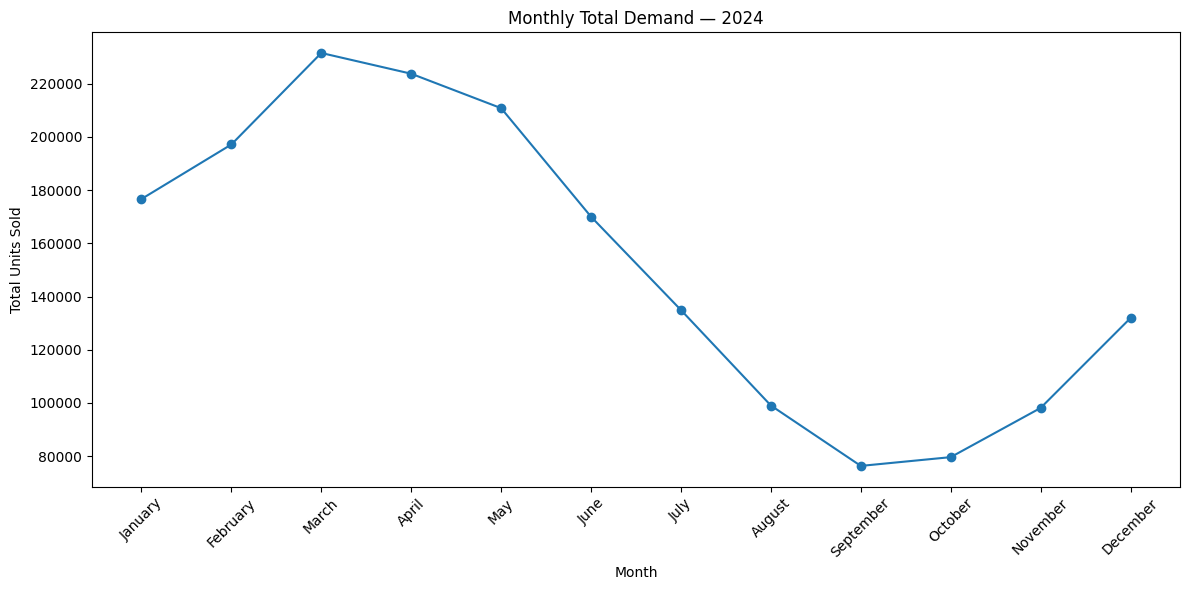

In [37]:
import matplotlib.pyplot as plt

# Plot monthly total demand

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_demand["month_name"],
    monthly_demand["total_units_sold"],
    marker="o"
)

plt.title("Monthly Total Demand — 2024")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [47]:
# Calculate total and average demand by SKU

sku_demand = (
    df.groupby("sku_id")
    .agg(
        total_units_sold=("units_sold", "sum"),
        Average_units_sold_per_SKU_Warehouse=("units_sold", "mean")
    )
    .sort_values("total_units_sold", ascending=False)
)

sku_demand.head(10)

,total_units_sold,Average_units_sold_per_SKU_Warehouse
sku_id,,
SKU_18,37234,20.402192
SKU_1,37026,20.288219
SKU_33,37012,20.280548
SKU_13,36915,20.227397
SKU_47,36912,20.225753
SKU_9,36855,20.194521
SKU_4,36811,20.170411
SKU_12,36794,20.161096
SKU_3,36785,20.156164


In [44]:
# Identify the 10 lowest-demand SKUs

sku_demand_lowest = (
    sku_demand
    .sort_values("total_units_sold", ascending=True)
)

sku_demand_lowest.head(10)

,total_units_sold,Average_units_sold_per_SKU_Warehouse
sku_id,,
SKU_6,36213,19.842740
SKU_19,36255,19.865753
SKU_46,36270,19.873973
SKU_45,36347,19.916164
SKU_11,36358,19.922192
SKU_24,36381,19.934795
SKU_15,36397,19.943562
SKU_26,36398,19.944110
SKU_21,36406,19.948493


In [48]:
# Calculate each SKU's contribution to total demand

sku_demand_contribution = sku_demand.copy()

total_sku_demand = sku_demand_contribution["total_units_sold"].sum()

sku_demand_contribution["demand_contribution_pct"] = (
    sku_demand_contribution["total_units_sold"]
    / total_sku_demand
) * 100

sku_demand_contribution["cumulative_demand_pct"] = (
    sku_demand_contribution["demand_contribution_pct"]
    .cumsum()
)

sku_demand_contribution.head(10)

,total_units_sold,Average_units_sold_per_SKU_Warehouse,demand_contribution_pct,cumulative_demand_pct
sku_id,,,,
SKU_18,37234,20.402192,2.034668,2.034668
SKU_1,37026,20.288219,2.023302,4.057970
SKU_33,37012,20.280548,2.022537,6.080507
SKU_13,36915,20.227397,2.017236,8.097743
SKU_47,36912,20.225753,2.017072,10.114816
SKU_9,36855,20.194521,2.013958,12.128773
SKU_4,36811,20.170411,2.011553,14.140326
SKU_12,36794,20.161096,2.010624,16.150950
SKU_3,36785,20.156164,2.010132,18.161083


In [49]:
# Measure demand concentration across SKUs

top_10_demand_pct = (
    sku_demand_contribution.head(10)["demand_contribution_pct"].sum()
)

top_20_demand_pct = (
    sku_demand_contribution.head(20)["demand_contribution_pct"].sum()
)

top_50pct_sku_count = int(len(sku_demand_contribution) * 0.50)

top_50pct_demand_pct = (
    sku_demand_contribution.head(top_50pct_sku_count)
    ["demand_contribution_pct"]
    .sum()
)

print(f"Top 10 SKUs demand contribution : {top_10_demand_pct:.2f}%")
print(f"Top 20 SKUs demand contribution : {top_20_demand_pct:.2f}%")
print(
    f"Top 50% of SKUs demand contribution "
    f"({top_50pct_sku_count} SKUs): {top_50pct_demand_pct:.2f}%"
)

Top 10 SKUs demand contribution : 20.17%
Top 20 SKUs demand contribution : 40.22%
Top 50% of SKUs demand contribution (25 SKUs): 50.22%


In [50]:
# Calculate demand by warehouse

warehouse_demand = (
    df.groupby("warehouse_id")
    .agg(
        total_units_sold=("units_sold", "sum"),
        average_units_sold=("units_sold", "mean")
    )
    .sort_values("total_units_sold", ascending=False)
)

warehouse_demand

,total_units_sold,average_units_sold
warehouse_id,,
WH_1,366902,20.104219
WH_3,366110,20.060822
WH_2,366078,20.059068
WH_4,365775,20.042466
WH_5,365114,20.006247


In [55]:
# Calculate demand by region

region_demand = (
    df.groupby("region")
    .agg(
        total_units_sold=("units_sold", "sum"),
        average_units_sold=("units_sold", "mean")
    )
    .sort_values("total_units_sold", ascending=False)
)

region_demand

,total_units_sold,average_units_sold
region,,
East,459961,20.055856
North,459849,20.016062
South,456954,20.112412
West,453215,20.034259


In [52]:
# Compare demand on promotion vs non-promotion days

promotion_demand = (
    df.groupby("promotion_flag")["units_sold"]
    .agg(["count", "mean", "sum"])
    .rename(columns={
        "count": "record_count",
        "mean": "average_units_sold",
        "sum": "total_units_sold"
    })
)

promotion_demand

,record_count,average_units_sold,total_units_sold
promotion_flag,,,
0,81980,19.504977,1599018
1,9270,24.914887,230961


In [53]:
# Measure demand variability for each SKU

sku_demand_variability = (
    df.groupby("sku_id")["units_sold"]
    .agg(
        average_demand="mean",
        demand_std_dev="std"
    )
)

sku_demand_variability["coefficient_of_variation"] = (
    sku_demand_variability["demand_std_dev"]
    / sku_demand_variability["average_demand"]
)

sku_demand_variability = (
    sku_demand_variability
    .sort_values("coefficient_of_variation", ascending=False)
)

sku_demand_variability.head(10)

,average_demand,demand_std_dev,coefficient_of_variation
sku_id,,,
SKU_29,20.129863,9.402146,0.467074
SKU_7,19.979178,9.263599,0.463663
SKU_46,19.873973,9.202135,0.463024
SKU_26,19.944110,9.228825,0.462734
SKU_21,19.948493,9.225761,0.462479
SKU_8,20.110685,9.268463,0.460873
SKU_28,19.989589,9.199507,0.460215
SKU_27,19.957808,9.171064,0.459523
SKU_22,20.080000,9.201757,0.458255


In [54]:
# Evaluate the existing demand forecast

mae = df["absolute_forecast_error"].mean()

bias = df["forecast_error"].mean()

wape = (
    df["absolute_forecast_error"].sum()
    / df["units_sold"].sum()
) * 100

print(f"Mean Absolute Error (MAE) : {mae:.2f} units")
print(f"Forecast Bias             : {bias:.2f} units")
print(f"WAPE                      : {wape:.2f}%")

Mean Absolute Error (MAE) : 2.38 units
Forecast Bias             : -0.03 units
WAPE                      : 11.87%


Our key findings so far

Demand trend: Strong annual/seasonal pattern.

Weekly effect: Very small difference across weekdays.

SKU demand: Relatively evenly distributed.

Warehouse demand: Very evenly distributed.

Regional demand: Very evenly distributed.

Promotion: Promoted observations show ~27.7% higher average demand than non-promoted observations, though this is an association rather than proof of causality.

Demand variability: Some SKUs have materially higher relative variability, with the highest observed CV around 46.7%.

Existing forecast: MAE = 2.38, Bias ≈ -0.03, WAPE = 11.87%.

In [56]:
# Inventory overview statistics

inventory_stats = df["inventory_level"].describe()

inventory_stats

count    91250.000000
mean       471.522312
std        133.488002
min        168.000000
25%        370.000000
50%        461.000000
75%        564.000000
max        990.000000
Name: inventory_level, dtype: float64

In [57]:
# Calculate total inventory units

total_inventory_units = df["inventory_level"].sum()

print(f"Total inventory units across all observations: {total_inventory_units:,.0f}")

Total inventory units across all observations: 43,026,411


In [62]:
daily_inventory = (
    df.groupby("date", as_index=False)["inventory_level"]
    .sum()
    .rename(columns={"inventory_level": "total_inventory_units"})
)

daily_inventory.head(10)

,date,total_inventory_units
0,2024-01-01,180329
1,2024-01-02,175257
2,2024-01-03,169979
3,2024-01-04,164835
4,2024-01-05,159627
5,2024-01-06,154449
6,2024-01-07,149408
7,2024-01-08,145389
8,2024-01-09,140470
9,2024-01-10,138187


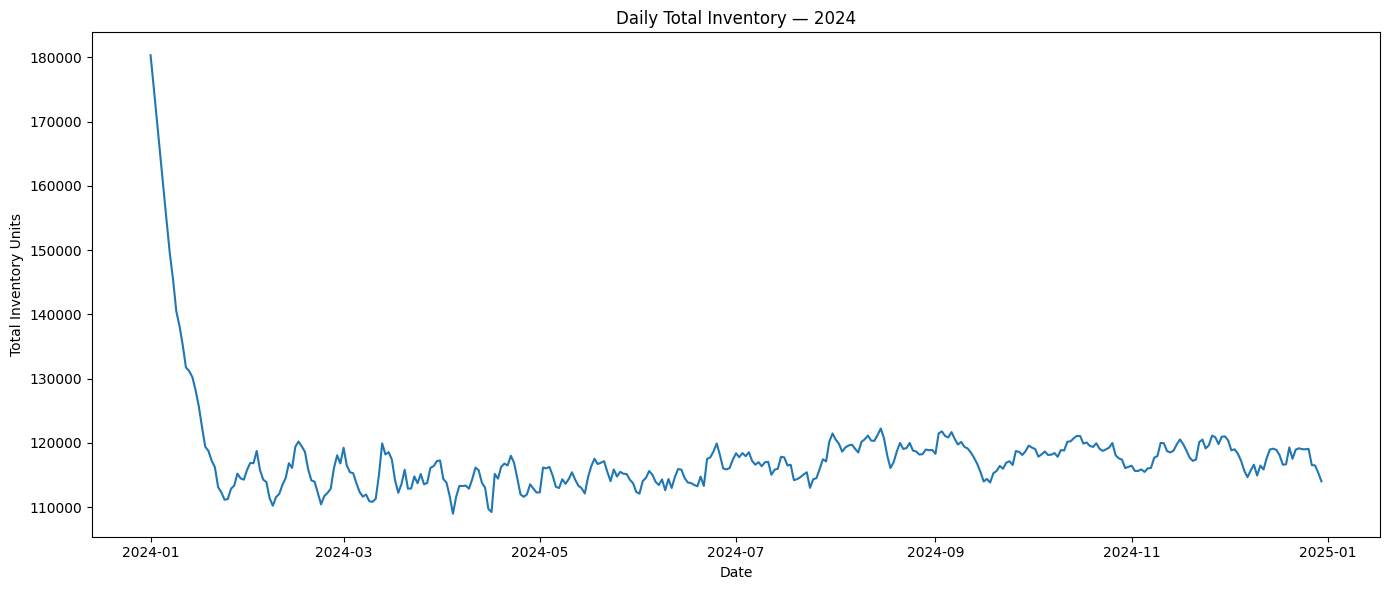

In [63]:
import matplotlib.pyplot as plt

# Plot total inventory over time

plt.figure(figsize=(14, 6))

plt.plot(
    daily_inventory["date"],
    daily_inventory["total_inventory_units"]
)

plt.title("Daily Total Inventory — 2024")
plt.xlabel("Date")
plt.ylabel("Total Inventory Units")

plt.tight_layout()
plt.show()

In [64]:
# Calculate total inventory value by day

daily_inventory_value = (
    df.groupby("date", as_index=False)["inventory_value"]
    .sum()
    .rename(columns={"inventory_value": "total_inventory_value"})
)

daily_inventory_value.head(10)

,date,total_inventory_value
0,2024-01-01,2212967.58
1,2024-01-02,2150844.16
2,2024-01-03,2086327.86
3,2024-01-04,2023767.03
4,2024-01-05,1959884.17
5,2024-01-06,1896833.60
6,2024-01-07,1835502.12
7,2024-01-08,1783677.08
8,2024-01-09,1721202.24
9,2024-01-10,1698046.42


In [65]:
# Calculate daily inventory value statistics

inventory_value_stats = (
    daily_inventory_value["total_inventory_value"]
    .describe()
)

inventory_value_stats

count    3.650000e+02
mean     1.439025e+06
std      9.716313e+04
min      1.320157e+06
25%      1.396347e+06
50%      1.425915e+06
75%      1.453693e+06
max      2.212968e+06
Name: total_inventory_value, dtype: float64

In [66]:
inventory_coverage_stats = (
    df["inventory_coverage_days"]
    .describe()
)

inventory_coverage_stats

count    90630.000000
mean        33.548068
std         41.053051
min          3.945455
25%         16.280000
50%         23.571429
75%         36.769231
max        816.000000
Name: inventory_coverage_days, dtype: float64

In [67]:
# Segment inventory coverage using the dataset quartiles

coverage_q1 = df["inventory_coverage_days"].quantile(0.25)
coverage_q3 = df["inventory_coverage_days"].quantile(0.75)

df["coverage_segment"] = np.select(
    [
        df["inventory_coverage_days"] < coverage_q1,
        df["inventory_coverage_days"] <= coverage_q3,
        df["inventory_coverage_days"] > coverage_q3
    ],
    [
        "Low Coverage",
        "Normal Coverage",
        "High Coverage"
    ],
    default="Not Applicable"
)

coverage_segment_summary = (
    df["coverage_segment"]
    .value_counts()
    .rename_axis("coverage_segment")
    .reset_index(name="record_count")
)

coverage_segment_summary["percentage"] = (
    coverage_segment_summary["record_count"]
    / len(df)
) * 100

coverage_segment_summary

,coverage_segment,record_count,percentage
0,Normal Coverage,45320,49.665753
1,High Coverage,22656,24.828493
2,Low Coverage,22654,24.826301
3,Not Applicable,620,0.679452


In [68]:
# Measure the correlation between inventory and actual demand

inventory_demand_corr = df[
    ["inventory_level", "units_sold"]
].corr()

inventory_demand_corr

,inventory_level,units_sold
inventory_level,1.000000,-0.064285
units_sold,-0.064285,1.000000


Business Interpretation
It suggests that inventory levels are not simply moving in proportion to that day's sales.
However, we should not conclude that inventory is poorly managed based on this correlation alone.

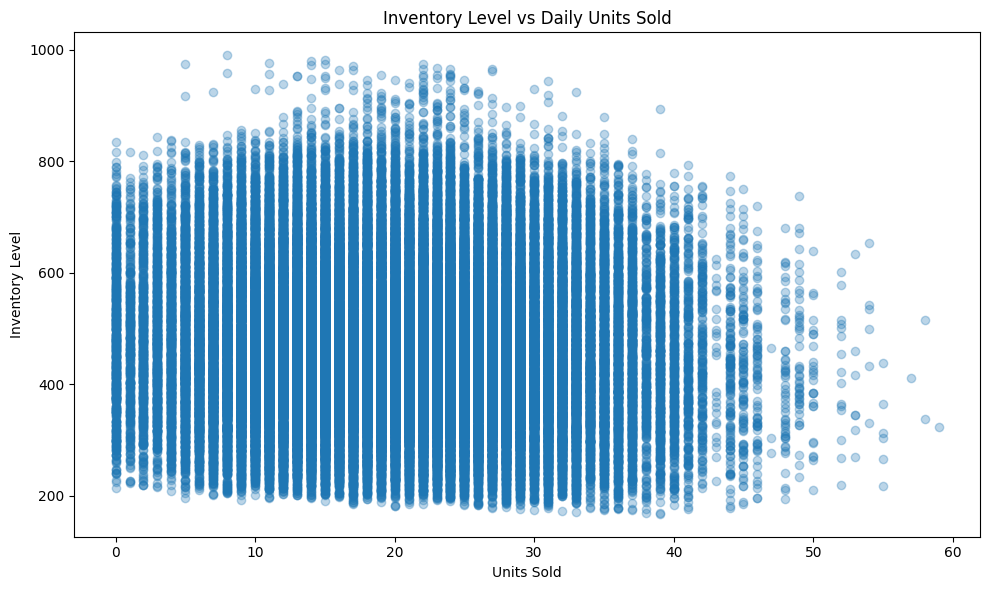

In [69]:
# Visualize the relationship between daily demand and inventory

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df["units_sold"],
    df["inventory_level"],
    alpha=0.3
)

plt.title("Inventory Level vs Daily Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Inventory Level")

plt.tight_layout()
plt.show()

And the scatter plot confirms our earlier correlation result.
What the chart shows
The points form a large, dispersed cloud rather than a clear upward or downward line.
So, at the overall SKU-Warehouse-Day level, there is very little linear relationship between current inventory and that day's sales.
That tells us:
## Inventory is not being set simply as a fixed multiple of daily sales.

In [ ]:
# Reorder Status Analysis
# Analyze inventory status relative to the reorder point

reorder_status_summary = (
    df["reorder_status"]
    .value_counts()
    .rename_axis("reorder_status")
    .reset_index(name="record_count")
)

reorder_status_summary["percentage"] = (
    reorder_status_summary["record_count"]
    / len(df)
) * 100

reorder_status_summary

,reorder_status,record_count,percentage
0,Above Reorder Point,86209,94.475616
1,Below Reorder Point,4787,5.246027
2,At Reorder Point,254,0.278356


In [71]:
# Analyze inventory by SKU

sku_inventory = (
    df.groupby("sku_id")
    .agg(
        average_inventory_units=("inventory_level", "mean"),
        average_inventory_value=("inventory_value", "mean")
    )
    .sort_values("average_inventory_value", ascending=False)
)

sku_inventory.head(10)

,average_inventory_units,average_inventory_value
sku_id,,
SKU_38,477.363288,8961.501277
SKU_48,484.007123,7515.024553
SKU_11,500.064658,7486.426510
SKU_40,472.634521,7456.362877
SKU_31,465.242740,6954.804822
SKU_13,485.848219,6851.744805
SKU_46,466.394521,6818.560838
SKU_32,465.961644,6763.426745
SKU_22,457.368767,6676.936258


In [72]:
# Identify SKUs with the lowest average inventory value

sku_inventory_lowest = (
    sku_inventory
    .sort_values("average_inventory_value", ascending=True)
)

sku_inventory_lowest.head(10)

,average_inventory_units,average_inventory_value
sku_id,,
SKU_44,430.552877,3260.712537
SKU_34,445.990137,3480.785649
SKU_25,467.837808,4332.109929
SKU_14,445.760548,4349.286532
SKU_5,457.352329,4619.174981
SKU_36,465.532055,4675.149693
SKU_30,437.898630,4750.678274
SKU_42,485.337534,4793.566729
SKU_50,408.510685,4800.902471


This means a SKU can have relatively high physical inventory but still have relatively low inventory investment if its unit cost is lower.

In [73]:
# Calculate each SKU's contribution to total average inventory value

inventory_value_concentration = sku_inventory.copy()

total_average_inventory_value = (
    inventory_value_concentration["average_inventory_value"].sum()
)

inventory_value_concentration["inventory_value_contribution_pct"] = (
    inventory_value_concentration["average_inventory_value"]
    / total_average_inventory_value
) * 100

inventory_value_concentration = (
    inventory_value_concentration
    .sort_values(
        "average_inventory_value",
        ascending=False
    )
)

inventory_value_concentration["cumulative_inventory_value_pct"] = (
    inventory_value_concentration[
        "inventory_value_contribution_pct"
    ].cumsum()
)

inventory_value_concentration.head(10)

,average_inventory_units,average_inventory_value,inventory_value_contribution_pct,cumulative_inventory_value_pct
sku_id,,,,
SKU_38,477.363288,8961.501277,3.113741,3.113741
SKU_48,484.007123,7515.024553,2.611152,5.724894
SKU_11,500.064658,7486.426510,2.601216,8.326109
SKU_40,472.634521,7456.362877,2.590770,10.916879
SKU_31,465.242740,6954.804822,2.416500,13.333378
SKU_13,485.848219,6851.744805,2.380691,15.714069
SKU_46,466.394521,6818.560838,2.369161,18.083230
SKU_32,465.961644,6763.426745,2.350004,20.433233
SKU_22,457.368767,6676.936258,2.319952,22.753185


In [74]:
# Measure inventory value concentration across SKUs

top_10_inventory_value_pct = (
    inventory_value_concentration
    .head(10)["inventory_value_contribution_pct"]
    .sum()
)

top_20_inventory_value_pct = (
    inventory_value_concentration
    .head(20)["inventory_value_contribution_pct"]
    .sum()
)

top_50pct_inventory_value_pct = (
    inventory_value_concentration
    .head(25)["inventory_value_contribution_pct"]
    .sum()
)

print(
    f"Top 10 SKUs inventory value contribution : "
    f"{top_10_inventory_value_pct:.2f}%"
)

print(
    f"Top 20 SKUs inventory value contribution : "
    f"{top_20_inventory_value_pct:.2f}%"
)

print(
    f"Top 50% of SKUs inventory value contribution : "
    f"{top_50pct_inventory_value_pct:.2f}%"
)

Top 10 SKUs inventory value contribution : 25.02%
Top 20 SKUs inventory value contribution : 46.92%
Top 50% of SKUs inventory value contribution : 57.21%


Inventory value is more concentrated than demand
The top 50% of SKUs generate about 50.22% of demand, but represent about 57.21% of average inventory value.
That means the inventory investment is somewhat more concentrated than consumption.

In [75]:
# Analyze inventory by warehouse

warehouse_inventory = (
    df.groupby("warehouse_id")
    .agg(
        average_inventory_units=("inventory_level", "mean"),
        average_inventory_value=("inventory_value", "mean")
    )
    .sort_values("average_inventory_value", ascending=False)
)

warehouse_inventory

,average_inventory_units,average_inventory_value
warehouse_id,,
WH_2,491.489644,6651.993201
WH_5,467.116329,5859.060656
WH_4,477.390301,5539.914563
WH_1,466.056219,5406.145554
WH_3,455.559068,5323.378690


In [76]:
# Compare warehouse demand and inventory

warehouse_comparison = warehouse_demand.join(
    warehouse_inventory,
    how="inner"
)

warehouse_comparison

,total_units_sold,average_units_sold,average_inventory_units,average_inventory_value
warehouse_id,,,,
WH_1,366902,20.104219,466.056219,5406.145554
WH_3,366110,20.060822,455.559068,5323.378690
WH_2,366078,20.059068,491.489644,6651.993201
WH_4,365775,20.042466,477.390301,5539.914563
WH_5,365114,20.006247,467.116329,5859.060656


In [77]:
# Calculate inventory-to-demand ratio by warehouse

warehouse_comparison["inventory_to_demand_ratio"] = (
    warehouse_comparison["average_inventory_units"]
    / warehouse_comparison["average_units_sold"]
)

warehouse_comparison[
    [
        "total_units_sold",
        "average_units_sold",
        "average_inventory_units",
        "average_inventory_value",
        "inventory_to_demand_ratio"
    ]
]

,total_units_sold,average_units_sold,average_inventory_units,average_inventory_value,inventory_to_demand_ratio
warehouse_id,,,,,
WH_1,366902,20.104219,466.056219,5406.145554,23.182010
WH_3,366110,20.060822,455.559068,5323.378690,22.708894
WH_2,366078,20.059068,491.489644,6651.993201,24.502117
WH_4,365775,20.042466,477.390301,5539.914563,23.818941
WH_5,365114,20.006247,467.116329,5859.060656,23.348524


In [17]:
# Identify potential inventory pressure

df["inventory_pressure"] = np.select(
    [
        (
            (df["inventory_level"] < df["reorder_point"]) &
            (df["inventory_coverage_days"] < df["supplier_lead_time_days"])
        ),
        (
            (df["inventory_level"] < df["reorder_point"]) &
            (df["inventory_coverage_days"] >= df["supplier_lead_time_days"])
        ),
        (
            df["inventory_level"] >= df["reorder_point"]
        )
    ],
    [
        "High Pressure",
        "Reorder Point Breach",
        "No Immediate Pressure"
    ],
    default="Not Applicable"
)

inventory_pressure_summary = (
    df["inventory_pressure"]
    .value_counts()
    .rename_axis("inventory_pressure")
    .reset_index(name="record_count")
)

inventory_pressure_summary["percentage"] = (
    inventory_pressure_summary["record_count"]
    / len(df)
) * 100

inventory_pressure_summary

,inventory_pressure,record_count,percentage
0,No Immediate Pressure,86463,94.753973
1,Reorder Point Breach,3607,3.952877
2,High Pressure,1180,1.293151


In [4]:
# Inventory Pressure by SKU
# Analyze high inventory pressure by SKU

sku_pressure = (
    df.groupby("sku_id")
    .agg(
        total_observations=("sku_id", "size"),
        high_pressure_records=(
            "inventory_pressure",
            lambda x: (x == "High Pressure").sum()
        )
    )
)

sku_pressure["high_pressure_pct"] = (
    sku_pressure["high_pressure_records"]
    / sku_pressure["total_observations"]
) * 100

sku_pressure = (
    sku_pressure
    .sort_values("high_pressure_pct", ascending=False)
)

sku_pressure.head(10)

,total_observations,high_pressure_records,high_pressure_pct
sku_id,,,
SKU_3,1825,47,2.575342
SKU_50,1825,46,2.520548
SKU_9,1825,43,2.356164
SKU_38,1825,43,2.356164
SKU_29,1825,42,2.301370
SKU_36,1825,40,2.191781
SKU_10,1825,40,2.191781
SKU_6,1825,39,2.136986
SKU_23,1825,38,2.082192


In [ ]:
# Inventory Pressure by Warehouse
# Analyze high inventory pressure by warehouse

warehouse_pressure = (
    df.groupby("warehouse_id")
    .agg(
        total_observations=("warehouse_id", "size"),
        high_pressure_records=(
            "inventory_pressure",
            lambda x: (x == "High Pressure").sum()
        )
    )
)

warehouse_pressure["high_pressure_pct"] = (
    warehouse_pressure["high_pressure_records"]
    / warehouse_pressure["total_observations"]
) * 100

warehouse_pressure = (
    warehouse_pressure
    .sort_values("high_pressure_pct", ascending=False)
)

warehouse_pressure

,total_observations,high_pressure_records,high_pressure_pct
warehouse_id,,,
WH_1,18250,263,1.441096
WH_3,18250,262,1.435616
WH_4,18250,259,1.419178
WH_2,18250,223,1.221918
WH_5,18250,173,0.947945


In [6]:
# Analyze inventory pressure by month

monthly_inventory_pressure = (
    df.groupby(["year", "month", "month_name"])
    .agg(
        total_observations=("inventory_pressure", "size"),
        high_pressure_records=(
            "inventory_pressure",
            lambda x: (x == "High Pressure").sum()
        )
    )
    .reset_index()
    .sort_values(["year", "month"])
)

monthly_inventory_pressure["high_pressure_pct"] = (
    monthly_inventory_pressure["high_pressure_records"]
    / monthly_inventory_pressure["total_observations"]
) * 100

monthly_inventory_pressure

,year,month,month_name,total_observations,high_pressure_records,high_pressure_pct
0,2024,1,January,7750,65,0.838710
1,2024,2,February,7250,183,2.524138
2,2024,3,March,7750,258,3.329032
3,2024,4,April,7500,242,3.226667
4,2024,5,May,7750,191,2.464516
5,2024,6,June,7500,111,1.480000
6,2024,7,July,7750,48,0.619355
7,2024,8,August,7750,10,0.129032
8,2024,9,September,7500,6,0.080000
9,2024,10,October,7750,6,0.077419


“Inventory pressure is highest during the March–April high-demand period and lowest during September–October, indicating that replenishment pressure varies substantially across the annual demand cycle.”

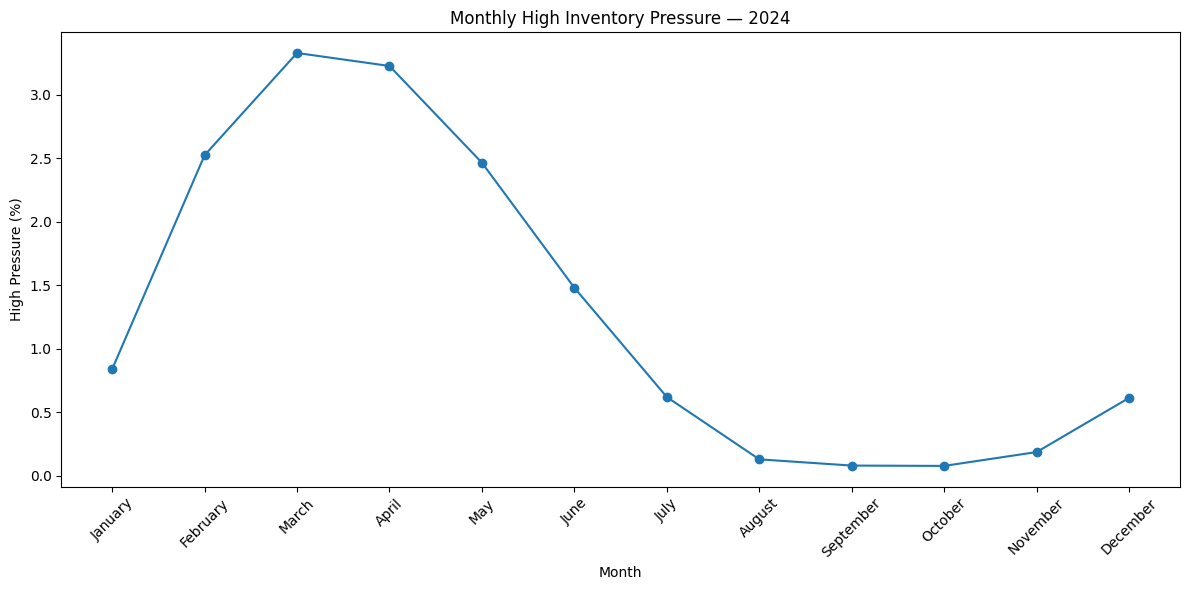

In [7]:
# Visualize monthly inventory pressure

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_inventory_pressure["month_name"],
    monthly_inventory_pressure["high_pressure_pct"],
    marker="o"
)

plt.title("Monthly High Inventory Pressure — 2024")
plt.xlabel("Month")
plt.ylabel("High Pressure (%)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Supply & Replenishment Analysis
# Analyze replenishment order quantities

order_records = df[df["order_quantity"] > 0]["order_quantity"]

order_quantity_stats = order_records.describe()

print("Replenishment order statistics:")
print(order_quantity_stats)

print(
    f"\nNumber of replenishment records: "
    f"{len(order_records):,}"
)

print(
    f"Total replenishment quantity: "
    f"{order_records.sum():,.0f}"
)

Replenishment order statistics:
count    5027.000000
mean      349.833897
std        86.192751
min       200.000000
25%       276.000000
50%       351.000000
75%       425.000000
max       499.000000
Name: order_quantity, dtype: float64

Number of replenishment records: 5,027
Total replenishment quantity: 1,758,615


In [9]:
# Calculate replenishment frequency by SKU and warehouse

replenishment_frequency = (
    df.groupby(["sku_id", "warehouse_id"])
    .agg(
        total_days=("date", "nunique"),
        replenishment_days=(
            "order_quantity",
            lambda x: (x > 0).sum()
        ),
        total_order_quantity=("order_quantity", "sum")
    )
)

replenishment_frequency["replenishment_frequency_pct"] = (
    replenishment_frequency["replenishment_days"]
    / replenishment_frequency["total_days"]
) * 100

replenishment_frequency = (
    replenishment_frequency
    .sort_values(
        "replenishment_frequency_pct",
        ascending=False
    )
)

replenishment_frequency.head(10)

,,total_days,replenishment_days,total_order_quantity,replenishment_frequency_pct
sku_id,warehouse_id,,,,
SKU_18,WH_5,365,24,7758,6.575342
SKU_8,WH_4,365,23,7320,6.301370
SKU_38,WH_3,365,23,7371,6.301370
SKU_20,WH_1,365,23,7418,6.301370
SKU_7,WH_4,365,23,7385,6.301370
SKU_12,WH_2,365,23,7259,6.301370
SKU_22,WH_5,365,23,7351,6.301370
SKU_14,WH_2,365,23,7047,6.301370
SKU_49,WH_1,365,22,7422,6.027397


In [12]:
# Analyze the most common replenishment order quantities

order_quantity_frequency = (
    order_records
    .value_counts()
    .sort_index()
    .reset_index()
)

order_quantity_frequency.columns = [
    "order_quantity",
    "order_count"
]

order_quantity_frequency["order_percentage"] = (
    order_quantity_frequency["order_count"]
    / len(order_records)
) * 100

order_quantity_frequency = (
    order_quantity_frequency
    .sort_values("order_count", ascending=False)
    .reset_index(drop=True)
)

order_quantity_frequency.head(15)

,order_quantity,order_count,order_percentage
0,386,29,0.576885
1,413,28,0.556992
2,426,28,0.556992
3,218,28,0.556992
4,440,27,0.537100
5,429,27,0.537100
6,257,26,0.517207
7,453,26,0.517207
8,209,26,0.517207
9,201,25,0.497315


In [13]:
# Check how frequently an order quantity of 470 occurs

order_470_count = (
    (df["order_quantity"] == 470).sum()
)

order_470_pct = (
    order_470_count / len(order_records)
) * 100

print(f"Orders with quantity 470: {order_470_count:,}")
print(f"Percentage of replenishment orders: {order_470_pct:.2f}%")

Orders with quantity 470: 23
Percentage of replenishment orders: 0.46%


In [6]:
# Validate the day-to-day inventory flow for each SKU-Warehouse combination

df = df.sort_values(
    ["sku_id", "warehouse_id", "date"]
).copy()

# Get the previous day's inventory for each SKU-Warehouse combination
df["previous_inventory"] = (
    df.groupby(["sku_id", "warehouse_id"])["inventory_level"]
    .shift(1)
)

# Calculate expected current inventory based on the inventory flow
df["expected_inventory"] = (
    df["previous_inventory"]
    + df["order_quantity"]
    - df["units_sold"]
)

# Calculate the difference between expected and actual inventory
df["inventory_flow_difference"] = (
    df["inventory_level"]
    - df["expected_inventory"]
)

# Check only records where a previous day's inventory exists
flow_check = df[
    df["previous_inventory"].notna()
]

print(
    "Records checked:",
    f"{len(flow_check):,}"
)

print(
    "Records where inventory flow matches exactly:",
    f"{(flow_check['inventory_flow_difference'] == 0).sum():,}"
)

print(
    "Records with inventory flow mismatch:",
    f"{(flow_check['inventory_flow_difference'] != 0).sum():,}"
)

Records checked: 91,000
Records where inventory flow matches exactly: 91,000
Records with inventory flow mismatch: 0


In [7]:
# Calculate inventory position immediately before replenishment

order_flow = df[
    (df["order_quantity"] > 0) &
    (df["previous_inventory"].notna())
].copy()

order_flow["pre_order_rop_gap"] = (
    order_flow["previous_inventory"]
    - order_flow["reorder_point"]
)

order_flow[
    [
        "date",
        "sku_id",
        "warehouse_id",
        "previous_inventory",
        "reorder_point",
        "pre_order_rop_gap",
        "order_quantity"
    ]
].head(10)

,date,sku_id,warehouse_id,previous_inventory,reorder_point,pre_order_rop_gap,order_quantity
11,2024-01-12,SKU_1,WH_1,362.0,379,-17.0,470
30,2024-01-31,SKU_1,WH_1,375.0,379,-4.0,397
45,2024-02-15,SKU_1,WH_1,377.0,379,-2.0,343
58,2024-02-28,SKU_1,WH_1,358.0,379,-21.0,245
66,2024-03-07,SKU_1,WH_1,357.0,379,-22.0,212
73,2024-03-14,SKU_1,WH_1,369.0,379,-10.0,204
81,2024-03-22,SKU_1,WH_1,364.0,379,-15.0,246
89,2024-03-30,SKU_1,WH_1,357.0,379,-22.0,463
102,2024-04-12,SKU_1,WH_1,374.0,379,-5.0,452
118,2024-04-28,SKU_1,WH_1,370.0,379,-9.0,377


In [16]:
# Measure the relationship between pre-order ROP gap and order quantity

rop_gap_order_corr = (
    order_flow[
        ["pre_order_rop_gap", "order_quantity"]
    ]
    .corr()
)

rop_gap_order_corr

,pre_order_rop_gap,order_quantity
pre_order_rop_gap,1.000000,0.003992
order_quantity,0.003992,1.000000


In [17]:
# Measure the relationship between pre-order inventory and order quantity

pre_order_inventory_corr = (
    order_flow[
        ["previous_inventory", "order_quantity"]
    ]
    .corr()
)

pre_order_inventory_corr

,previous_inventory,order_quantity
previous_inventory,1.00000,0.01229
order_quantity,0.01229,1.00000


In [18]:
# Measure the relationship between reorder point and order quantity

reorder_point_order_corr = (
    order_flow[
        ["reorder_point", "order_quantity"]
    ]
    .corr()
)

reorder_point_order_corr

,reorder_point,order_quantity
reorder_point,1.000000,0.011797
order_quantity,0.011797,1.000000


In [19]:
# Analyze replenishment order quantity by SKU

sku_order_quantity = (
    order_flow.groupby("sku_id")
    .agg(
        replenishment_orders=("order_quantity", "count"),
        total_order_quantity=("order_quantity", "sum"),
        average_order_quantity=("order_quantity", "mean"),
        median_order_quantity=("order_quantity", "median")
    )
    .sort_values(
        "average_order_quantity",
        ascending=False
    )
)

sku_order_quantity.head(10)

,replenishment_orders,total_order_quantity,average_order_quantity,median_order_quantity
sku_id,,,,
SKU_27,94,34930,371.595745,380.0
SKU_31,96,35554,370.354167,376.0
SKU_41,98,35966,367.000000,371.0
SKU_47,97,35486,365.835052,377.0
SKU_16,99,35819,361.808081,351.0
SKU_33,99,35666,360.262626,367.0
SKU_38,98,35252,359.714286,365.5
SKU_25,100,35777,357.770000,356.0
SKU_34,97,34702,357.752577,362.0


In [20]:
# Inspect every replenishment order where quantity = 470

orders_470 = (
    order_flow[
        order_flow["order_quantity"] == 470
    ]
    [
        [
            "date",
            "sku_id",
            "warehouse_id",
            "supplier_id",
            "previous_inventory",
            "reorder_point",
            "pre_order_rop_gap",
            "units_sold",
            "order_quantity"
        ]
    ]
    .sort_values("date")
)

orders_470

,date,sku_id,warehouse_id,supplier_id,previous_inventory,reorder_point,pre_order_rop_gap,units_sold,order_quantity
11,2024-01-12,SKU_1,WH_1,SUP_8,362.0,379,-17.0,29,470
42373,2024-02-03,SKU_24,WH_2,SUP_7,347.0,365,-18.0,34,470
35449,2024-02-14,SKU_20,WH_3,SUP_3,296.0,319,-23.0,28,470
11365,2024-02-20,SKU_7,WH_2,SUP_8,381.0,396,-15.0,23,470
23776,2024-02-21,SKU_14,WH_1,SUP_2,248.0,265,-17.0,34,470
72333,2024-03-04,SKU_40,WH_4,SUP_10,234.0,255,-21.0,35,470
13570,2024-03-06,SKU_8,WH_3,SUP_7,190.0,207,-17.0,39,470
75632,2024-03-18,SKU_42,WH_3,SUP_2,361.0,367,-6.0,33,470
28917,2024-03-23,SKU_16,WH_5,SUP_5,371.0,394,-23.0,30,470
84762,2024-03-23,SKU_47,WH_3,SUP_7,354.0,377,-23.0,32,470


“The analysis reverse-engineered the inventory flow and tested potential replenishment drivers. While replenishment timing is associated with inventory falling below the reorder point, the supplied order quantities do not show a meaningful linear relationship with pre-order inventory, reorder-point gap, or reorder point.”

In [21]:
# Analyze replenishment order quantity by supplier

supplier_order_quantity = (
    order_flow.groupby("supplier_id")
    .agg(
        replenishment_orders=("order_quantity", "count"),
        total_order_quantity=("order_quantity", "sum"),
        average_order_quantity=("order_quantity", "mean"),
        median_order_quantity=("order_quantity", "median")
    )
    .sort_values(
        "average_order_quantity",
        ascending=False
    )
)

supplier_order_quantity

,replenishment_orders,total_order_quantity,average_order_quantity,median_order_quantity
supplier_id,,,,
SUP_5,455,162347,356.806593,361.0
SUP_7,679,239283,352.405007,353.0
SUP_2,526,184645,351.036122,352.0
SUP_4,504,176568,350.333333,357.0
SUP_1,557,195080,350.233393,349.0
SUP_10,544,189525,348.391544,346.5
SUP_9,322,112062,348.018634,343.5
SUP_6,407,141361,347.324324,347.0
SUP_3,466,161721,347.040773,352.5


In [25]:
# Analyze 470-unit orders by supplier

orders_470_by_supplier = (
    orders_470
    .groupby("supplier_id")
    .size()
    .reset_index(name="orders_470")
    .sort_values("orders_470", ascending=False)
)

orders_470_by_supplier

,supplier_id,orders_470
3,SUP_3,6
0,SUP_1,4
2,SUP_2,4
6,SUP_7,4
7,SUP_8,2
1,SUP_10,1
4,SUP_4,1
5,SUP_5,1


In [23]:
# Calculate the percentage of each supplier's orders that are exactly 470 units

supplier_470_rate = (
    order_flow
    .groupby("supplier_id")
    .agg(
        total_replenishment_orders=("order_quantity", "count"),
        orders_470=("order_quantity", lambda x: (x == 470).sum())
    )
)

supplier_470_rate["percentage_470"] = (
    supplier_470_rate["orders_470"]
    / supplier_470_rate["total_replenishment_orders"]
) * 100

supplier_470_rate = (
    supplier_470_rate
    .sort_values("percentage_470", ascending=False)
)

supplier_470_rate

,total_replenishment_orders,orders_470,percentage_470
supplier_id,,,
SUP_3,466,6,1.287554
SUP_2,526,4,0.760456
SUP_1,557,4,0.718133
SUP_7,679,4,0.589102
SUP_8,567,2,0.352734
SUP_5,455,1,0.219780
SUP_4,504,1,0.198413
SUP_10,544,1,0.183824
SUP_6,407,0,0.000000


In [26]:
# Analyze 470-unit orders by month

orders_470_by_month = (
    orders_470
    .assign(month=orders_470["date"].dt.month,
            month_name=orders_470["date"].dt.month_name())
    .groupby(["month", "month_name"])
    .size()
    .reset_index(name="orders_470")
    .sort_values("month")
)

orders_470_by_month

,month,month_name,orders_470
0,1,January,1
1,2,February,4
2,3,March,6
3,5,May,3
4,6,June,2
5,7,July,2
6,9,September,1
7,11,November,3
8,12,December,1


In [27]:
# Calculate the percentage of monthly replenishment orders that are exactly 470 units

monthly_470_rate = (
    order_flow
    .assign(
        month=order_flow["date"].dt.month,
        month_name=order_flow["date"].dt.month_name()
    )
    .groupby(["month", "month_name"])
    .agg(
        total_replenishment_orders=("order_quantity", "count"),
        orders_470=("order_quantity", lambda x: (x == 470).sum())
    )
    .reset_index()
    .sort_values("month")
)

monthly_470_rate["percentage_470"] = (
    monthly_470_rate["orders_470"]
    / monthly_470_rate["total_replenishment_orders"]
) * 100

monthly_470_rate

,month,month_name,total_replenishment_orders,orders_470,percentage_470
0,1,January,304,1,0.328947
1,2,February,561,4,0.713012
2,3,March,658,6,0.911854
3,4,April,629,0,0.000000
4,5,May,606,3,0.495050
5,6,June,506,2,0.395257
6,7,July,400,2,0.500000
7,8,August,273,0,0.000000
8,9,September,225,1,0.444444
9,10,October,219,0,0.000000


In [28]:
# Measure the relationship between demand-related variables and order quantity

demand_order_corr = (
    order_flow[
        [
            "units_sold",
            "demand_forecast",
            "lead_time_demand",
            "order_quantity"
        ]
    ]
    .corr()
)

demand_order_corr

,units_sold,demand_forecast,lead_time_demand,order_quantity
units_sold,1.000000,0.948499,0.599949,0.008447
demand_forecast,0.948499,1.000000,0.573903,0.006378
lead_time_demand,0.599949,0.573903,1.000000,-0.005504
order_quantity,0.008447,0.006378,-0.005504,1.000000


In [ ]:
## Test Whether Order Quantity Is Uniformly Distributed
## Test the distribution of replenishment order quantities

unique_order_quantities = order_records.nunique()
minimum_order_quantity = order_records.min()
maximum_order_quantity = order_records.max()
mean_order_quantity = order_records.mean()
std_order_quantity = order_records.std()

expected_mean = (200 + 499) / 2

expected_std = np.sqrt(
    ((499 - 200 + 1) ** 2 - 1) / 12
)

print(f"Unique order quantities : {unique_order_quantities}")
print(f"Minimum order quantity : {minimum_order_quantity}")
print(f"Maximum order quantity : {maximum_order_quantity}")

print(f"\nObserved mean          : {mean_order_quantity:.2f}")
print(f"Expected uniform mean  : {expected_mean:.2f}")

print(f"\nObserved std. dev.     : {std_order_quantity:.2f}")
print(f"Expected uniform std.  : {expected_std:.2f}")

Unique order quantities : 300
Minimum order quantity : 200
Maximum order quantity : 499

Observed mean          : 349.83
Expected uniform mean  : 349.50

Observed std. dev.     : 86.19
Expected uniform std.  : 86.60


The observed order quantities are highly consistent with a discrete uniform distribution over integers 200–499, suggesting that the field may have been synthetically generated within this bounded range rather than calculated from the visible inventory-planning variables

In [33]:
from scipy.stats import chisquare

# Count how many times each possible order quantity occurs
observed_counts = (
    order_records
    .value_counts()
    .reindex(range(200, 500), fill_value=0)
)

# Under a uniform distribution, every quantity should occur equally often
expected_count = len(order_records) / 300

expected_counts = np.full(
    300,
    expected_count
)

# Perform Chi-square goodness-of-fit test
chi_stat, p_value = chisquare(
    f_obs=observed_counts.values,
    f_exp=expected_counts
)

print(f"Chi-square statistic : {chi_stat:.2f}")
print(f"P-value              : {p_value:.4f}")

print(
    f"\nExpected frequency per quantity: "
    f"{expected_count:.2f}"
)

print(
    f"Minimum observed frequency: "
    f"{observed_counts.min()}"
)

print(
    f"Maximum observed frequency: "
    f"{observed_counts.max()}"
)

Chi-square statistic : 324.24
P-value              : 0.1511

Expected frequency per quantity: 16.76
Minimum observed frequency: 5
Maximum observed frequency: 29


## Replenishment Quantity Logic — Key Finding

The dataset's `order_quantity` field was investigated to determine whether replenishment quantities are driven by inventory position, reorder point, demand, or supplier characteristics.

The analysis found:

- 5,027 replenishment orders were identified.
- Order quantities range from 200 to 499 units.
- All 300 integer values between 200 and 499 occur in the dataset.
- Observed mean order quantity = 349.83 units.
- Theoretical uniform mean = 349.50 units.
- Observed standard deviation = 86.19 units.
- Theoretical uniform standard deviation = 86.60 units.
- Chi-square goodness-of-fit test p-value = 0.1511.

At the 5% significance level, there is insufficient evidence to reject the hypothesis that order quantities follow a discrete uniform distribution across 200–499.

Additional correlation analysis showed virtually no linear relationship between order quantity and:
- Previous inventory
- Reorder-point gap
- Reorder point
- Actual demand
- Demand forecast
- Lead-time demand

Therefore, the supplied `order_quantity` appears to behave as a bounded synthetic/generated field rather than a quantity calculated from the visible inventory-planning variables.

The inventory movement itself is fully explained by:

**Current Inventory = Previous Inventory + Order Quantity − Units Sold**

This relationship matched all 91,000 records for which a previous-day inventory value was available.

In [14]:
# Calculate the number of days between replenishment orders

order_intervals = (
    order_flow
    .sort_values(["sku_id", "warehouse_id", "date"])
    .copy()
)

order_intervals["days_since_previous_order"] = (
    order_intervals
    .groupby(["sku_id", "warehouse_id"])["date"]
    .diff()
    .dt.days
)

# Summarize replenishment intervals by SKU and warehouse
    
replenishment_interval_summary = (
    order_intervals
    .dropna(subset=["days_since_previous_order"])
    .groupby(["sku_id", "warehouse_id"])
    .agg(
        replenishment_orders_after_first_order=("order_quantity", "count"),
        average_days_between_orders=(
            "days_since_previous_order",
            "mean"
        ),
        median_days_between_orders=(
            "days_since_previous_order",
            "median"
        ),
        minimum_days_between_orders=(
            "days_since_previous_order",
            "min"
        ),
        maximum_days_between_orders=(
            "days_since_previous_order",
            "max"
        )
    )
    .sort_values("average_days_between_orders")
)

replenishment_interval_summary.head(10)

,,replenishment_orders_after_first_order,average_days_between_orders,median_days_between_orders,minimum_days_between_orders,maximum_days_between_orders
sku_id,warehouse_id,,,,,
SKU_14,WH_2,22,14.954545,13.5,7.0,30.0
SKU_2,WH_2,21,15.047619,13.0,7.0,42.0
SKU_12,WH_2,22,15.409091,13.5,7.0,40.0
SKU_14,WH_5,21,15.428571,16.0,7.0,27.0
SKU_37,WH_4,21,15.428571,12.0,6.0,45.0
SKU_18,WH_5,23,15.434783,13.0,7.0,29.0
SKU_7,WH_4,22,15.636364,14.5,7.0,48.0
SKU_21,WH_5,21,15.666667,13.0,8.0,43.0
SKU_38,WH_3,22,15.863636,12.5,8.0,40.0


In [9]:
# Validate whether replenishment occurs when inventory reaches or falls below ROP

trigger_summary = {
    "Below ROP": (
        order_flow["previous_inventory"]
        < order_flow["reorder_point"]
    ).sum(),

    "At ROP": (
        order_flow["previous_inventory"]
        == order_flow["reorder_point"]
    ).sum(),

    "Above ROP": (
        order_flow["previous_inventory"]
        > order_flow["reorder_point"]
    ).sum()
}

trigger_summary_df = (
    pd.DataFrame(
        list(trigger_summary.items()),
        columns=["trigger_condition", "order_count"]
    )
)

trigger_summary_df["percentage"] = (
    trigger_summary_df["order_count"]
    / len(order_flow)
) * 100

trigger_summary_df

,trigger_condition,order_count,percentage
0,Below ROP,4773,94.947285
1,At ROP,254,5.052715
2,Above ROP,0,0.000000


In [8]:
# Does the Order Bring Inventory Back to a Target Level?
# Analyze inventory position immediately after replenishment

order_flow["inventory_after_receipt"] = (
    order_flow["previous_inventory"]
    + order_flow["order_quantity"]
)

order_flow["post_receipt_rop_gap"] = (
    order_flow["inventory_after_receipt"]
    - order_flow["reorder_point"]
)

post_order_inventory_stats = (
    order_flow["post_receipt_rop_gap"]
    .describe()
)

post_order_inventory_stats

count    5027.00000
mean      338.14442
std        86.65443
min       168.00000
25%       263.00000
50%       339.00000
75%       412.00000
max       499.00000
Name: post_receipt_rop_gap, dtype: float64

In [9]:
# Measure the relationship between order quantity
# and the inventory position after replenishment

post_receipt_corr = (
    order_flow[
        [
            "order_quantity",
            "post_receipt_rop_gap"
        ]
    ]
    .corr()
)

post_receipt_corr

,order_quantity,post_receipt_rop_gap
order_quantity,1.000000,0.995068
post_receipt_rop_gap,0.995068,1.000000


In [11]:
## Supplier Lead-Time Analysis
# Analyze supplier lead time by supplier

supplier_lead_time = (
    df.groupby("supplier_id")
    .agg(
        average_lead_time_days=("supplier_lead_time_days", "mean"),
        minimum_lead_time_days=("supplier_lead_time_days", "min"),
        maximum_lead_time_days=("supplier_lead_time_days", "max"),
        unique_lead_times=("supplier_lead_time_days", "nunique")
    )
    .sort_values(
        "average_lead_time_days",
        ascending=False
    )
)

supplier_lead_time

,average_lead_time_days,minimum_lead_time_days,maximum_lead_time_days,unique_lead_times
supplier_id,,,,
SUP_4,8.640000,3,14,10
SUP_8,8.500000,2,14,13
SUP_2,8.423077,2,14,11
SUP_3,8.260870,2,14,12
SUP_9,8.187500,2,14,12
SUP_1,8.107143,3,14,12
SUP_6,7.900000,2,14,11
SUP_7,7.558824,2,14,11
SUP_10,7.407407,2,14,10


In [12]:
# Measure supplier lead-time variability

supplier_lead_time_variability = (
    df.groupby("supplier_id")
    .agg(
        average_lead_time_days=("supplier_lead_time_days", "mean"),
        lead_time_std_dev=("supplier_lead_time_days", "std"),
        minimum_lead_time_days=("supplier_lead_time_days", "min"),
        maximum_lead_time_days=("supplier_lead_time_days", "max")
    )
    .sort_values(
        "lead_time_std_dev",
        ascending=False
    )
)

supplier_lead_time_variability

,average_lead_time_days,lead_time_std_dev,minimum_lead_time_days,maximum_lead_time_days
supplier_id,,,,
SUP_7,7.558824,4.506329,2,14
SUP_8,8.500000,4.204795,2,14
SUP_2,8.423077,4.087466,2,14
SUP_3,8.260870,4.024270,2,14
SUP_10,7.407407,3.793552,2,14
SUP_9,8.187500,3.762282,2,14
SUP_1,8.107143,3.569281,3,14
SUP_6,7.900000,3.562547,2,14
SUP_5,6.956522,3.419818,2,13


In [15]:
# Calculate average supplier lead time for each SKU-Warehouse combination

sku_warehouse_lead_time = (
    df.groupby(["sku_id", "warehouse_id"])
    .agg(
        average_lead_time_days=(
            "supplier_lead_time_days",
            "mean"
        )
    )
)

# Combine lead time with replenishment interval

lead_time_replenishment = (
    replenishment_interval_summary[
        ["average_days_between_orders"]
    ]
    .join(
        sku_warehouse_lead_time,
        how="inner"
    )
)

# Measure the relationship between lead time and replenishment interval

lead_time_interval_corr = (
    lead_time_replenishment[
        [
            "average_lead_time_days",
            "average_days_between_orders"
        ]
    ]
    .corr()
)

lead_time_interval_corr

,average_lead_time_days,average_days_between_orders
average_lead_time_days,1.000000,-0.040252
average_days_between_orders,-0.040252,1.000000


In [18]:
# Analyze inventory pressure across supplier lead-time groups

df["lead_time_group"] = pd.cut(
    df["supplier_lead_time_days"],
    bins=[0, 5, 10, 15],
    labels=["Short (2-5 days)", "Medium (6-10 days)", "Long (11-14 days)"]
)

lead_time_pressure = (
    df.groupby("lead_time_group", observed=False)
    .agg(
        total_observations=("inventory_pressure", "size"),
        high_pressure_records=(
            "inventory_pressure",
            lambda x: (x == "High Pressure").sum()
        )
    )
)

lead_time_pressure["high_pressure_pct"] = (
    lead_time_pressure["high_pressure_records"]
    / lead_time_pressure["total_observations"]
) * 100

lead_time_pressure

,total_observations,high_pressure_records,high_pressure_pct
lead_time_group,,,
Short (2-5 days),29930,6,0.020047
Medium (6-10 days),32120,299,0.930884
Long (11-14 days),29200,875,2.996575


In [19]:
# Compare inventory coverage with supplier lead time

df["coverage_vs_lead_time_gap"] = (
    df["inventory_coverage_days"]
    - df["supplier_lead_time_days"]
)

# Summarize the coverage gap

coverage_lead_time_stats = (
    df["coverage_vs_lead_time_gap"]
    .describe()
)

coverage_lead_time_stats

count    90630.000000
mean        25.564475
std         41.216020
min        -10.054545
25%          8.204691
50%         16.052632
75%         29.214286
max        811.000000
Name: coverage_vs_lead_time_gap, dtype: float64

In [20]:
# Classify inventory coverage relative to supplier lead time

coverage_cushion_summary = {
    "Coverage below lead time": (
        df["coverage_vs_lead_time_gap"] < 0
    ).sum(),

    "Coverage equal to lead time": (
        df["coverage_vs_lead_time_gap"] == 0
    ).sum(),

    "Coverage above lead time": (
        df["coverage_vs_lead_time_gap"] > 0
    ).sum()
}

coverage_cushion_summary_df = (
    pd.DataFrame(
        list(coverage_cushion_summary.items()),
        columns=["coverage_condition", "record_count"]
    )
)

valid_coverage_records = (
    df["coverage_vs_lead_time_gap"].notna().sum()
)

coverage_cushion_summary_df["percentage"] = (
    coverage_cushion_summary_df["record_count"]
    / valid_coverage_records
) * 100

coverage_cushion_summary_df

,coverage_condition,record_count,percentage
0,Coverage below lead time,4120,4.545956
1,Coverage equal to lead time,53,0.058480
2,Coverage above lead time,86457,95.395564


# Phase 3 — EDA Key Findings

## Demand

- Demand shows strong seasonality across 2024.
- March and April are the highest-demand months.
- September and October are among the lowest-demand periods.
- Demand is relatively similar across warehouses, with total annual demand close to 365K units per warehouse.
- The existing demand forecast has:
  - MAE = 2.38 units
  - Forecast Bias = -0.03 units
  - WAPE = 11.87%

## Inventory

- Average inventory level is approximately 471.5 units per SKU-Warehouse-Day.
- Median inventory is approximately 461 units.
- Daily network inventory falls sharply at the beginning of the year and then stabilizes within a lower operating range.
- Typical daily inventory value is approximately $1.44M.
- Median inventory coverage is approximately 23.57 days.
- Around 25% of valid observations fall into the lower coverage quartile and around 25% into the upper coverage quartile.
- Inventory and daily demand have almost no linear relationship at the overall observation level (correlation ≈ -0.064).
- 94.48% of observations are above the provided reorder point.
- Inventory value is somewhat more concentrated than demand:
  - Top 10 SKUs → 25.02% of average inventory value
  - Top 20 SKUs → 46.92%
  - Top 25 SKUs → 57.21%

## Inventory Pressure

- Overall High Pressure rate = 1.29%.
- High Pressure is highest during March–April and lowest during September–October.
- WH_1 has the highest warehouse High Pressure rate at approximately 1.44%.
- SKU_3 has the highest SKU-level High Pressure rate at approximately 2.57%.
- Longer lead-time groups show higher High Pressure rates; however, lead time is part of the High Pressure definition, so this relationship should not be interpreted as causal.

## Replenishment

- 5,027 replenishment orders were identified.
- Average order quantity = 349.83 units.
- Median order quantity = 351 units.
- Order quantities range from 200 to 499 units.
- All 300 integer quantities from 200 to 499 occur in the dataset.
- Order quantity is statistically consistent with a discrete uniform distribution over 200–499 (Chi-square p-value = 0.1511).
- Order quantity has virtually no linear relationship with previous inventory, reorder point, ROP gap, actual demand, forecast demand, or lead-time demand.
- Replenishment intervals are generally around 15–16 days for many SKU-Warehouse combinations, but intervals vary.
- 94.95% of replenishment orders occur when previous inventory is below ROP, while 5.05% occur exactly at ROP.
- No replenishment orders were observed while previous inventory was above ROP.

## Inventory Flow

The dataset's inventory movement is exactly explained by:

**Current Inventory = Previous Inventory + Order Quantity − Units Sold**

This relationship matched all 91,000 observations for which a previous-day inventory value was available.

The first 250 records (50 SKUs × 5 warehouses) cannot be validated using this equation because they are the first observation for each SKU-Warehouse combination and therefore have no previous-day inventory.

## Replenishment Quantity Limitation

The analysis could not identify a transparent business formula explaining how the individual `order_quantity` value is selected.

Therefore, the project does not assume an EOQ, minimum/maximum inventory, or order-up-to formula for the supplied order quantity.

This limitation will be addressed later by developing a business-driven replenishment recommendation model.